In [1]:
import matplotlib.pyplot as plt
from granad import *
import numpy as np

In [2]:
# Define flake and bulk (Periodic) structure 

# FLAKE
lattice_constant = 2.62 # Å
lattice_basis = [[1, 0, 0], [-0.5, jnp.sqrt(3)/2, 0]] 
au_s_hoppings = [-0.21 + 1.1, -0.58]   # PARAMETERS TUNED MANUALLY TO FIT THE EXPECTED ENERGY BAND :)

goldene = (Material("Au")
        .lattice_constant(lattice_constant)
        .lattice_basis(lattice_basis)
        .add_orbital_species("s_gold", atom='Au')
        .add_orbital(position=(0, 0), tag="Au_s", species="s_gold")
        .add_interaction(
            "hamiltonian",
            participants=("s_gold", "s_gold"),
            parameters=au_s_hoppings,  
        )   )
flake = goldene.cut_flake(Rectangle(0.5, 0.5), minimum_neighbor_number = 0)

# BULK
lattice_vectors = lattice_constant*jnp.array([
    [1, 0, 0],
    [-0.5, jnp.sqrt(3)/2, 0] ])
fourier_cutoff = 4
bulk = Periodic(flake, lattice_vectors, fourier_cutoff)

Mean energy: 0.8900000000000003, minimum: [-2.59], maximum: [2.6298061]
Mu Gauss is 1.3706100000155632


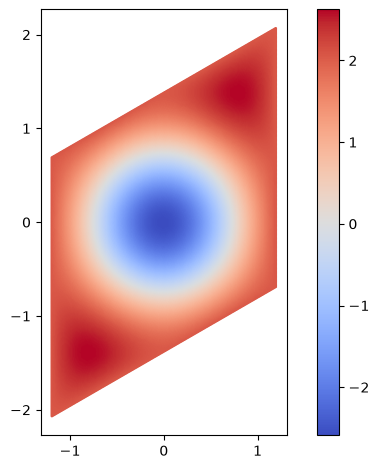

In [3]:
N_monkhorst = 199
ks = bulk.get_kgrid_monkhorst_pack([N_monkhorst, N_monkhorst])

energies, vecs = bulk.get_eigenbasis(ks)
print(f"Mean energy: {np.mean(energies)}, minimum: {min(energies)}, maximum: {max(energies)}")

mu_gauss = bulk.get_fermi_energy(energies, sigma=0.1, delta_e=1e-5)
print(f"Mu Gauss is {mu_gauss}")

fig, ax = plt.subplots()
plot1 = ax.scatter(ks[0], ks[1], c=energies, s=1, cmap="coolwarm")
ax.set_aspect("equal")
plt.colorbar(plot1, ax=ax)
plt.tight_layout()
plt.show()


Mean energy: 0.8889439735132868, minimum: [-2.59], maximum: [2.63]
Mu Gauss is 1.3687200000155508


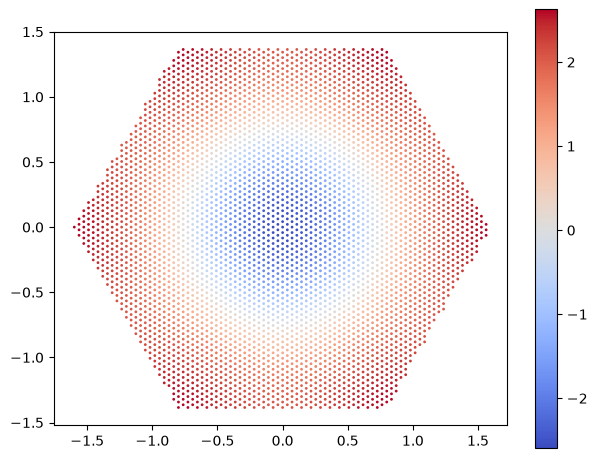

In [4]:
N_brillouin = 199
ks = bulk.get_first_brillouin_zone([N_brillouin, N_brillouin])

energies, vecs = bulk.get_eigenbasis(ks)
print(f"Mean energy: {np.mean(energies)}, minimum: {min(energies)}, maximum: {max(energies)}")

mu_gauss = bulk.get_fermi_energy(energies, sigma=0.1, delta_e=1e-5)
print(f"Mu Gauss is {mu_gauss}")

fig, ax = plt.subplots()
plot1 = ax.scatter(ks[0], ks[1], c=energies, s=1, cmap="coolwarm")
ax.set_aspect("equal")
plt.colorbar(plot1, ax=ax)
plt.tight_layout()
plt.show()

Mean energy: 0.8757280470219045, minimum: [-2.59], maximum: [2.63]
Mu Gauss is 1.3862300000156655


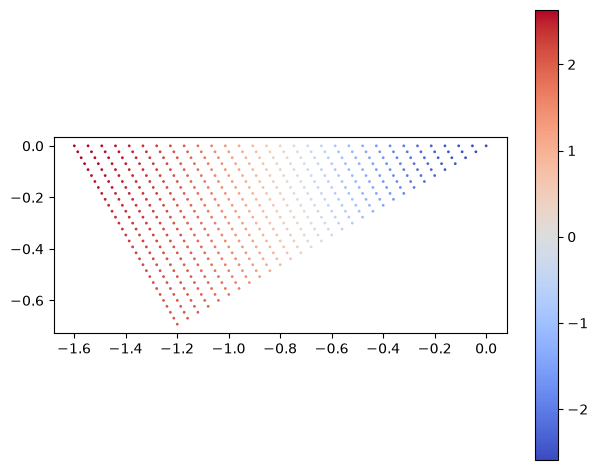

In [5]:
result = bulk.get_kgrid_folded(n=30)
ks = result["ks"]

energies, vecs = bulk.get_eigenbasis(ks)
print(f"Mean energy: {np.mean(energies)}, minimum: {min(energies)}, maximum: {max(energies)}")

mu_gauss = bulk.get_fermi_energy(energies, sigma=0.1, delta_e=1e-5)
print(f"Mu Gauss is {mu_gauss}")

fig, ax = plt.subplots()
plot1 = ax.scatter(ks[0], ks[1], c=energies, s=1, cmap="coolwarm")
ax.set_aspect("equal")
plt.colorbar(plot1, ax=ax)
plt.tight_layout()
plt.show()

Mean energy: 0.892172404901821, minimum: [-2.59], maximum: [2.63]
Mu Gauss is 1.3734100000155816


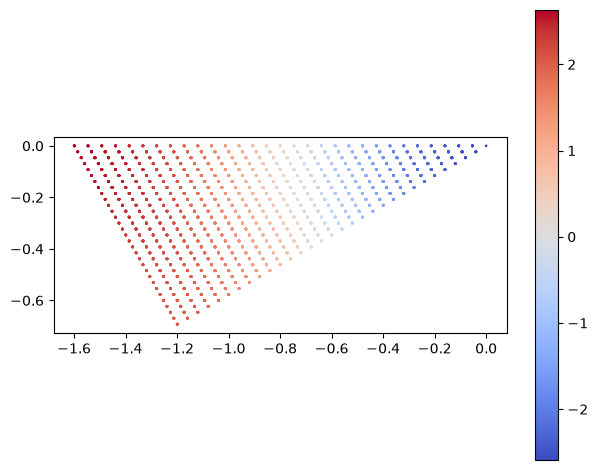

In [6]:
ks = bulk.get_kgrid_folded(n=30, expand=True)

energies, vecs = bulk.get_eigenbasis(ks)
print(f"Mean energy: {np.mean(energies)}, minimum: {min(energies)}, maximum: {max(energies)}")

mu_gauss = bulk.get_fermi_energy(energies, sigma=0.1, delta_e=1e-5)
print(f"Mu Gauss is {mu_gauss}")

fig, ax = plt.subplots()
plot1 = ax.scatter(ks[0], ks[1], c=energies, s=1, cmap="coolwarm")
plt.colorbar(plot1, ax=ax)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

Resolution 99. Mean energy: 0.8764521764734677, minimum: [-2.59], maximum: [2.61520701]
Resolution 132. Mean energy: 0.9015031496551019, minimum: [-2.58399835], maximum: [2.6298883]
Resolution 165. Mean energy: 0.8816288960954937, minimum: [-2.59], maximum: [2.62884834]
Resolution 198. Mean energy: 0.8972678979940081, minimum: [-2.58734549], maximum: [2.62936617]
Resolution 231. Mean energy: 0.8833507811210493, minimum: [-2.59], maximum: [2.62630006]
Resolution 264. Mean energy: 0.8953008691922272, minimum: [-2.58851049], maximum: [2.62883047]
Resolution 297. Mean energy: 0.8852617939325801, minimum: [-2.59], maximum: [2.62835521]
Resolution 330. Mean energy: 0.8944565298726296, minimum: [-2.58904813], maximum: [2.62998234]
Resolution 363. Mean energy: 0.8861072385791123, minimum: [-2.59], maximum: [2.62976548]
Resolution 396. Mean energy: 0.8936338077888557, minimum: [-2.58933963], maximum: [2.62984167]
Resolution 429. Mean energy: 0.8865250134316821, minimum: [-2.59], maximum: [2.628

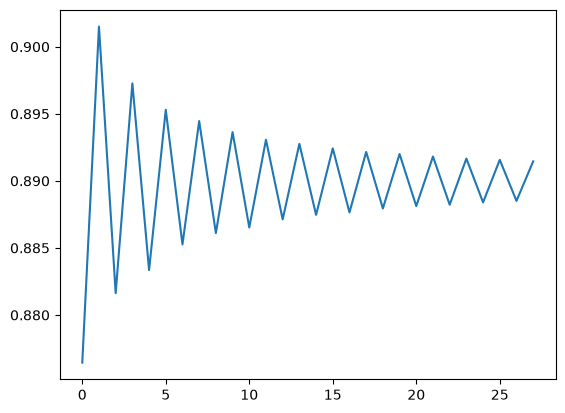

In [7]:
### For comparison, what seems to be the most accurate energy (full I BZ - increased sampling resolution)

mean_energy_list = []

for N_brillouin in range(99,999,33):
    ks = bulk.get_first_brillouin_zone([N_brillouin, N_brillouin])

    energies, vecs = bulk.get_eigenbasis(ks)
    print(f"Resolution {N_brillouin}. Mean energy: {np.mean(energies)}, minimum: {min(energies)}, maximum: {max(energies)}")
    mean_energy_list.append(np.mean(energies))

plt.plot(range(len(mean_energy_list)), mean_energy_list)
plt.show()
